In [1]:
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import numpy as np

In [6]:
df= pd.read_csv('vgsales.csv')

In [7]:
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [4]:
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [5]:
df['Year']= df['Year'].fillna(0)

In [6]:
df.Publisher = df.Publisher.fillna('Unknown')

In [7]:
df.isnull().sum()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

In [8]:
df.dtypes

Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

In [9]:
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')

In [10]:
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [11]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,1973.647307,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,254.346809,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [12]:
df.groupby('Genre')[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']].agg(['sum', 'mean'])

NA_Sales           EU_Sales           JP_Sales            \
                  sum      mean      sum      mean      sum      mean   
Genre                                                                   
Action         877.83  0.264726   525.00  0.158323   159.95  0.048236   
Adventure      105.80  0.082271    64.13  0.049868    52.07  0.040490   
Fighting       223.59  0.263667   101.32  0.119481    87.35  0.103007   
Misc           410.24  0.235906   215.98  0.124198   107.76  0.061967   
Platform       447.05  0.504571   201.63  0.227573   130.77  0.147596   
Puzzle         123.78  0.212680    50.78  0.087251    57.31  0.098471   
Racing         359.42  0.287766   238.39  0.190865    56.69  0.045388   
Role-Playing   327.28  0.219946   188.06  0.126384   352.31  0.236767   
Shooter        582.60  0.444733   313.27  0.239137    38.28  0.029221   
Simulation     183.31  0.211430   113.38  0.130773    63.70  0.073472   
Sports         683.35  0.291283   376.85  0.160635   135.37  0.057702   
Strategy        68.70  0.100881    45.34  0.066579    49.46  0.072628   

             Other_Sales            
                     sum      mean  
Genre                               
Action            187.38  0.056508  
Adventure          16.81  0.013072  
Fighting           36.68  0.043255  
Misc               75.32  0.043312  
Platform           51.59  0.058228  
Puzzle             12.55  0.021564  
Racing             77.27  0.061865  
Role-Playing       59.61  0.040060  
Shooter           102.69  0.078389  
Simulation         31.52  0.036355  
Sports            134.97  0.057532  
Strategy           11.36  0.016681

In [13]:
df.groupby('Platform')['Global_Sales'].agg(['sum','mean'])

,sum,mean
Platform,,
2600,97.08,0.729925
3DO,0.10,0.033333
3DS,247.46,0.486169
DC,15.97,0.307115
DS,822.49,0.380254
GB,255.45,2.606633
GBA,318.50,0.387470
GC,199.36,0.358561
GEN,28.36,1.050370


In [14]:
df.groupby('Genre')['Global_Sales'].agg(['sum','mean'])

,sum,mean
Genre,,
Action,1751.18,0.528100
Adventure,239.04,0.185879
Fighting,448.91,0.529375
Misc,809.96,0.465762
Platform,831.37,0.938341
Puzzle,244.95,0.420876
Racing,732.04,0.586101
Role-Playing,927.37,0.623233
Shooter,1037.37,0.791885


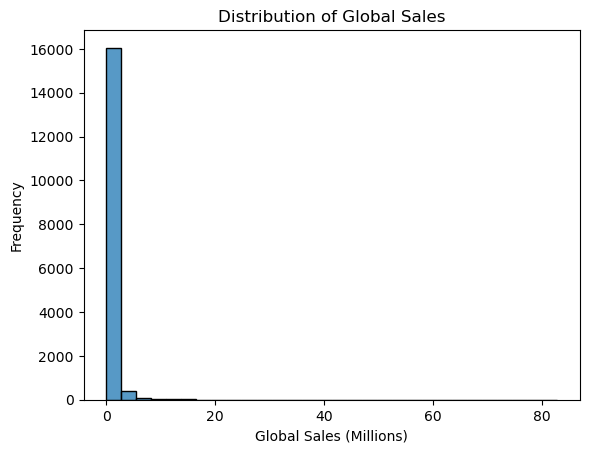

In [15]:
sb.histplot(data=df, x='Global_Sales', bins=30)
plt.title('Distribution of Global Sales')
plt.xlabel('Global Sales (Millions)')
plt.ylabel('Frequency')
plt.show()

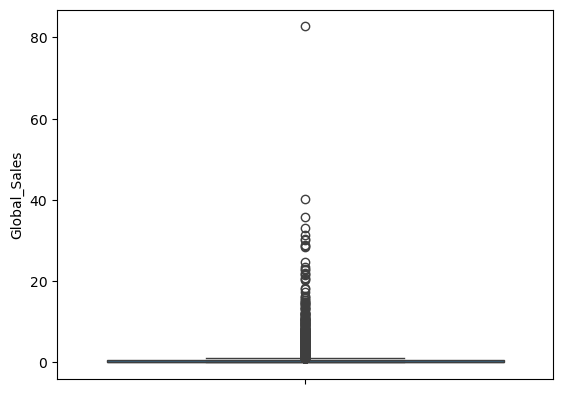

In [16]:
sb.boxplot(df.Global_Sales)
plt.show()

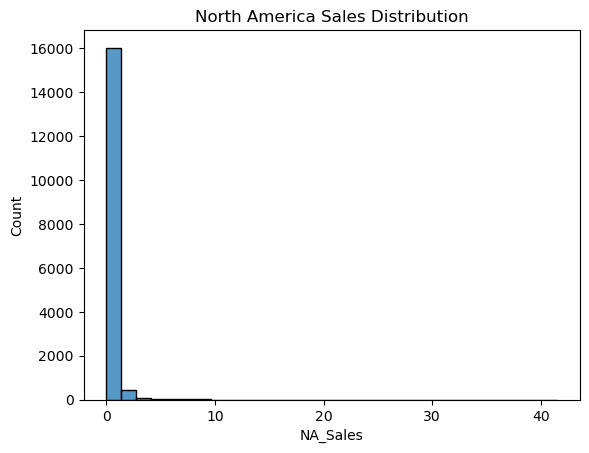

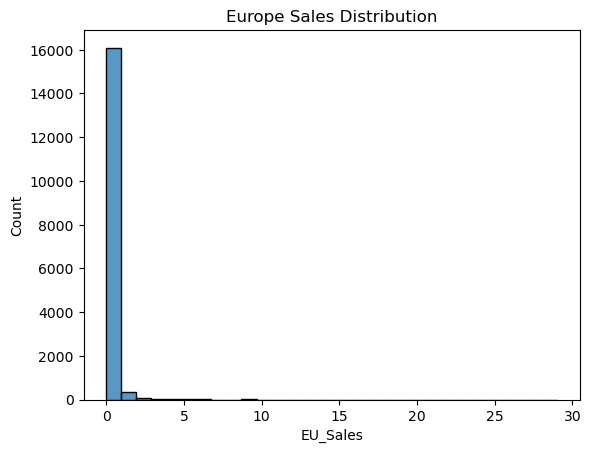

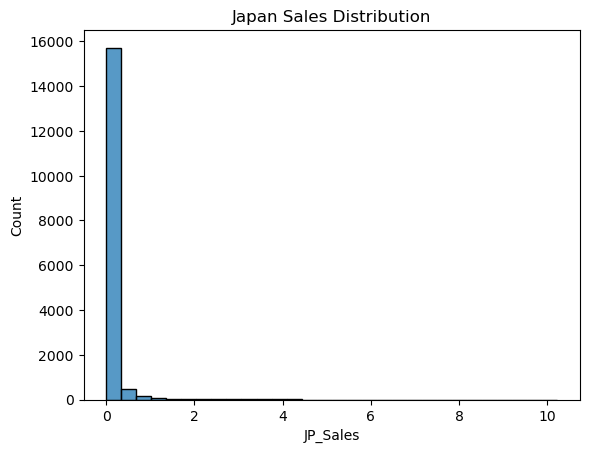

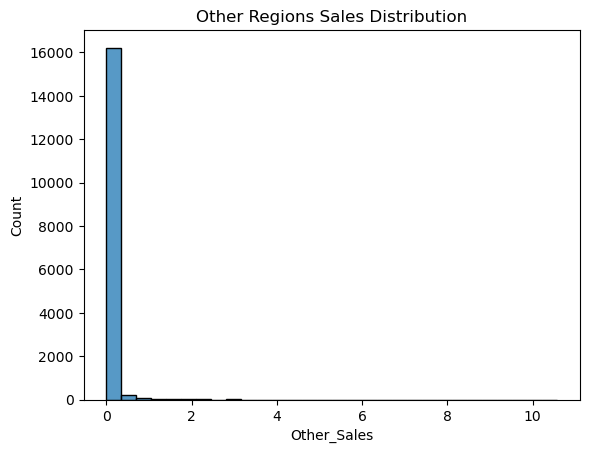

In [17]:
sb.histplot(data=df, x='NA_Sales', bins=30)
plt.title('North America Sales Distribution')
plt.show()

sb.histplot(data=df, x='EU_Sales', bins=30)
plt.title('Europe Sales Distribution')
plt.show()

sb.histplot(data=df, x='JP_Sales', bins=30)
plt.title('Japan Sales Distribution')
plt.show()

sb.histplot(data=df, x='Other_Sales', bins=30)
plt.title('Other Regions Sales Distribution')
plt.show()

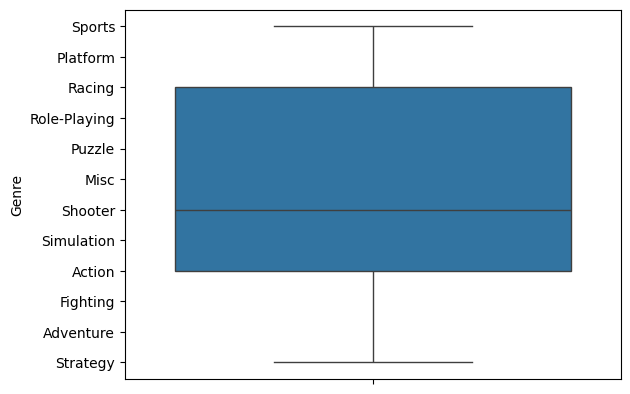

In [18]:
sb.boxplot(df.Genre)
plt.show()

In [19]:
#Top Selling Games:

In [20]:
df.sort_values(by='Global_Sales',ascending=False)[['Name', 'Global_Sales']].head(10)

,Name,Global_Sales
0,Wii Sports,82.74
1,Super Mario Bros.,40.24
2,Mario Kart Wii,35.82
3,Wii Sports Resort,33.00
4,Pokemon Red/Pokemon Blue,31.37
5,Tetris,30.26
6,New Super Mario Bros.,30.01
7,Wii Play,29.02
8,New Super Mario Bros. Wii,28.62
9,Duck Hunt,28.31


In [21]:
df.Global_Sales.sum()

8920.44

In [22]:
#Platform Performance:

In [23]:
df.groupby('Platform')['Global_Sales'].sum().nlargest()

Platform
PS2     1255.64
X360     979.96
PS3      957.84
Wii      926.71
DS       822.49
Name: Global_Sales, dtype: float64

In [24]:
top_games = df.loc[df.groupby('Year')['Global_Sales'].idxmax()]

p=top_games['Platform'].value_counts()
p

Platform
NES     6
GB      6
PS2     5
SNES    5
PS4     4
Wii     4
2600    3
X360    2
DS      2
PS3     2
PS      1
Name: count, dtype: int64

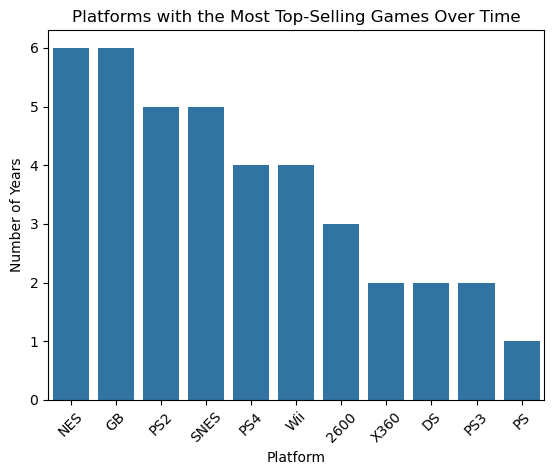

In [25]:
sb.barplot(x=p.index, y=p.values)
plt.title('Platforms with the Most Top-Selling Games Over Time')
plt.xlabel('Platform')
plt.ylabel('Number of Years')
plt.xticks(rotation=45)
plt.show()

In [26]:
p_sales= df.groupby('Platform')['Global_Sales'].sum().nlargest(10)
p_sales

Platform
PS2     1255.64
X360     979.96
PS3      957.84
Wii      926.71
DS       822.49
PS       730.66
GBA      318.50
PSP      296.28
PS4      278.10
PC       258.82
Name: Global_Sales, dtype: float64

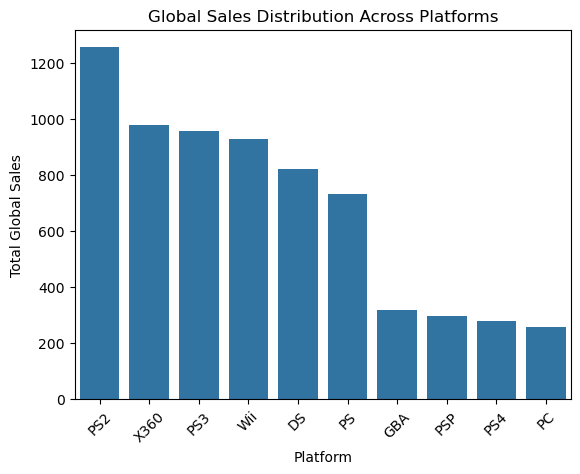

In [27]:
sb.barplot(x=p_sales.index, y=p_sales.values)
plt.title('Global Sales Distribution Across Platforms')
plt.xlabel('Platform')
plt.ylabel('Total Global Sales')
plt.xticks(rotation=45)
plt.show()

In [28]:
#Genre Analysis:

In [29]:
#1
df.groupby('Genre')['Global_Sales'].sum()

Genre
Action          1751.18
Adventure        239.04
Fighting         448.91
Misc             809.96
Platform         831.37
Puzzle           244.95
Racing           732.04
Role-Playing     927.37
Shooter         1037.37
Simulation       392.20
Sports          1330.93
Strategy         175.12
Name: Global_Sales, dtype: float64

In [30]:
#2
g_platform = pd.pivot_table(data=df,index='Genre', columns='Platform', values='Global_Sales',aggfunc='sum')
g_platform

Platform,2600,3DO,3DS,DC,DS,GB,GBA,GC,GEN,GG,...,SAT,SCD,SNES,TG16,WS,Wii,WiiU,X360,XB,XOne
Genre,,,,,,,,,,,,,,,,,,,,,
Action,29.34,NaN,57.02,1.26,115.56,7.92,55.76,37.84,2.74,NaN,...,0.65,NaN,10.08,NaN,NaN,118.58,19.35,242.67,49.28,33.79
Adventure,1.70,0.06,4.81,2.50,47.29,17.16,14.68,5.93,0.19,NaN,...,4.16,NaN,1.50,0.14,NaN,18.43,0.17,15.23,3.06,2.51
Fighting,1.24,NaN,10.46,1.83,7.20,NaN,4.21,18.43,5.90,NaN,...,8.52,NaN,26.95,NaN,NaN,23.86,6.36,37.64,13.55,2.31
Misc,3.58,NaN,10.48,NaN,137.76,13.35,36.25,16.73,0.03,NaN,...,1.20,0.10,5.02,NaN,NaN,221.06,12.23,91.96,9.58,6.86
Platform,13.27,NaN,32.23,2.54,77.45,54.91,78.30,28.66,15.45,0.04,...,0.76,1.50,65.65,NaN,NaN,90.74,21.24,11.39,9.66,0.81
Puzzle,14.68,0.02,5.57,NaN,84.29,47.47,12.92,4.70,NaN,NaN,...,1.00,NaN,6.38,NaN,NaN,15.67,1.33,0.85,0.42,NaN
Racing,2.91,NaN,14.49,2.65,38.64,4.55,18.80,21.89,0.26,NaN,...,2.40,0.07,13.49,NaN,NaN,61.28,7.77,65.99,31.49,8.80
Role-Playing,NaN,NaN,75.74,0.68,126.85,88.24,64.21,13.15,0.27,NaN,...,3.76,0.06,36.43,NaN,1.22,14.06,2.47,71.98,13.51,9.48
Shooter,26.48,NaN,1.29,0.33,8.20,1.20,3.60,13.63,0.13,NaN,...,3.98,NaN,6.07,0.02,NaN,28.77,6.17,278.55,63.55,51.61


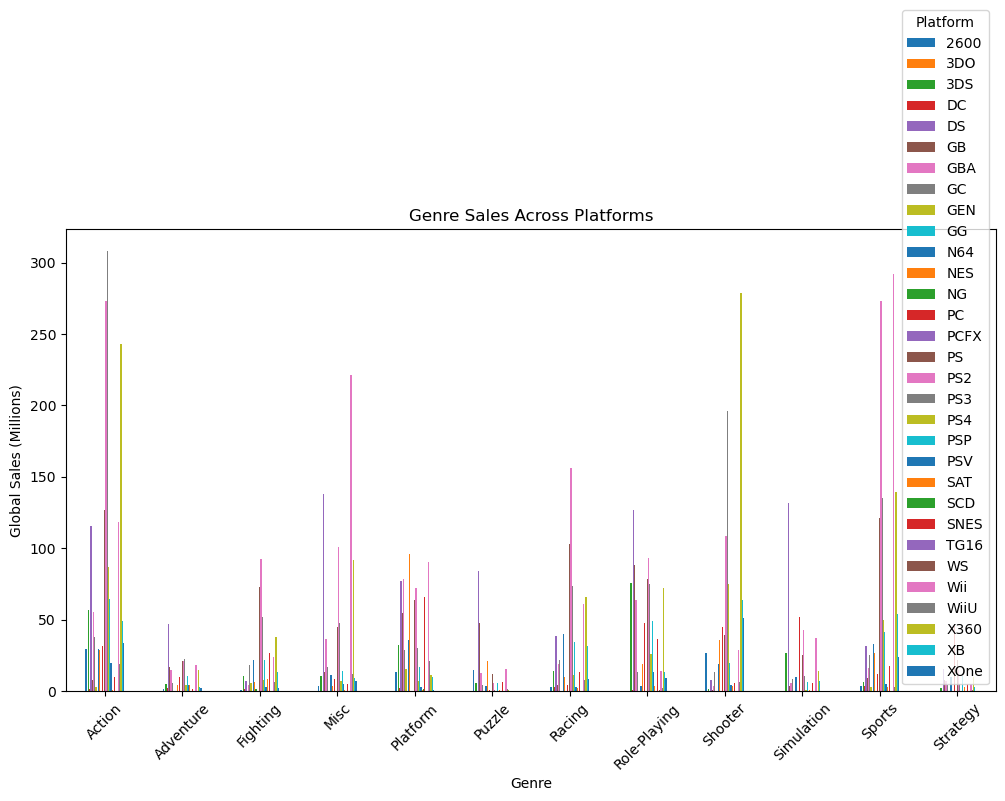

In [31]:
g_platform.plot(kind='bar', figsize=(12, 6))

plt.title('Genre Sales Across Platforms')
plt.xlabel('Genre')
plt.ylabel('Global Sales (Millions)')
plt.xticks(rotation=45)
plt.show()

In [32]:
g_region = df.groupby('Genre')[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']].sum()
g_region

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Genre,,,,
Action,877.83,525.00,159.95,187.38
Adventure,105.80,64.13,52.07,16.81
Fighting,223.59,101.32,87.35,36.68
Misc,410.24,215.98,107.76,75.32
Platform,447.05,201.63,130.77,51.59
Puzzle,123.78,50.78,57.31,12.55
Racing,359.42,238.39,56.69,77.27
Role-Playing,327.28,188.06,352.31,59.61
Shooter,582.60,313.27,38.28,102.69


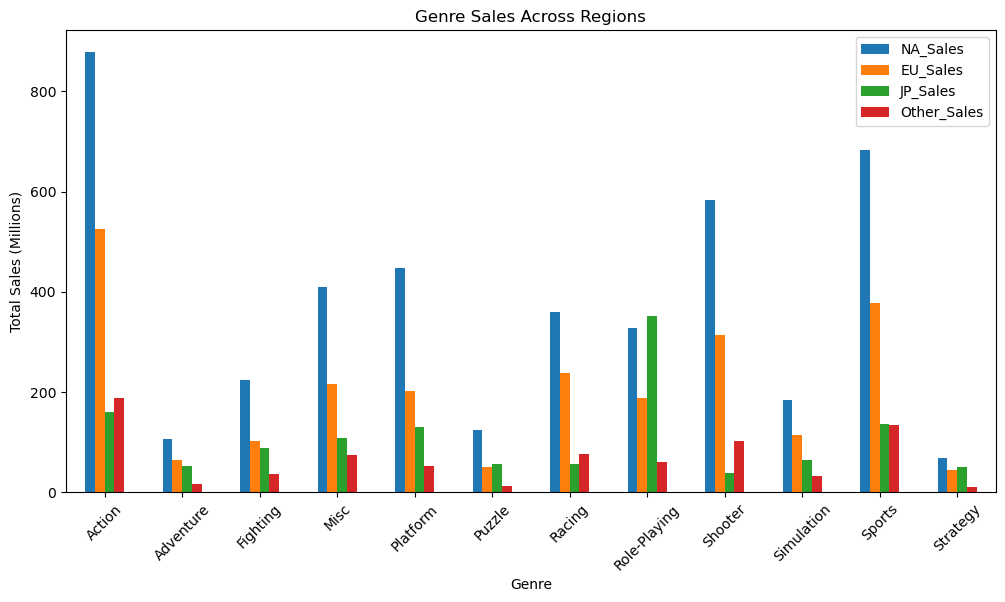

In [33]:
g_region.plot(kind='bar', figsize=(12, 6))

plt.title('Genre Sales Across Regions')
plt.xlabel('Genre')
plt.ylabel('Total Sales (Millions)')
plt.xticks(rotation=45)
plt.show()

In [34]:
#3
g_year=df.groupby(['Year','Genre'])['Global_Sales'].sum().reset_index()
g_year

,Year,Genre,Global_Sales
0,0.0,Action,28.30
1,0.0,Adventure,4.24
2,0.0,Fighting,4.86
3,0.0,Misc,12.34
4,0.0,Platform,2.22
...,...,...,...
396,2016.0,Sports,14.60
397,2016.0,Strategy,0.50
398,2017.0,Action,0.01
399,2017.0,Role-Playing,0.04


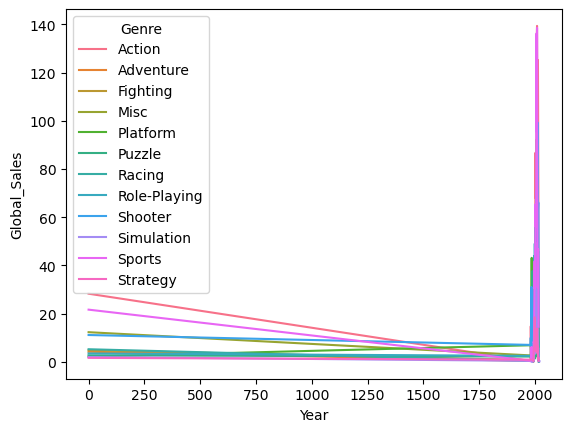

In [35]:
sb.lineplot(data=g_year, x='Year', y='Global_Sales', hue='Genre')
plt.show()

In [36]:
#Publisher Performance:

In [8]:
p_genre = df.groupby(['Genre','Publisher'])['Global_Sales'].sum().nlargest()
p_genre

Genre         Publisher      
Sports        Electronic Arts    479.67
Platform      Nintendo           427.21
Shooter       Activision         299.87
Role-Playing  Nintendo           284.90
Sports        Nintendo           218.01
Name: Global_Sales, dtype: float64

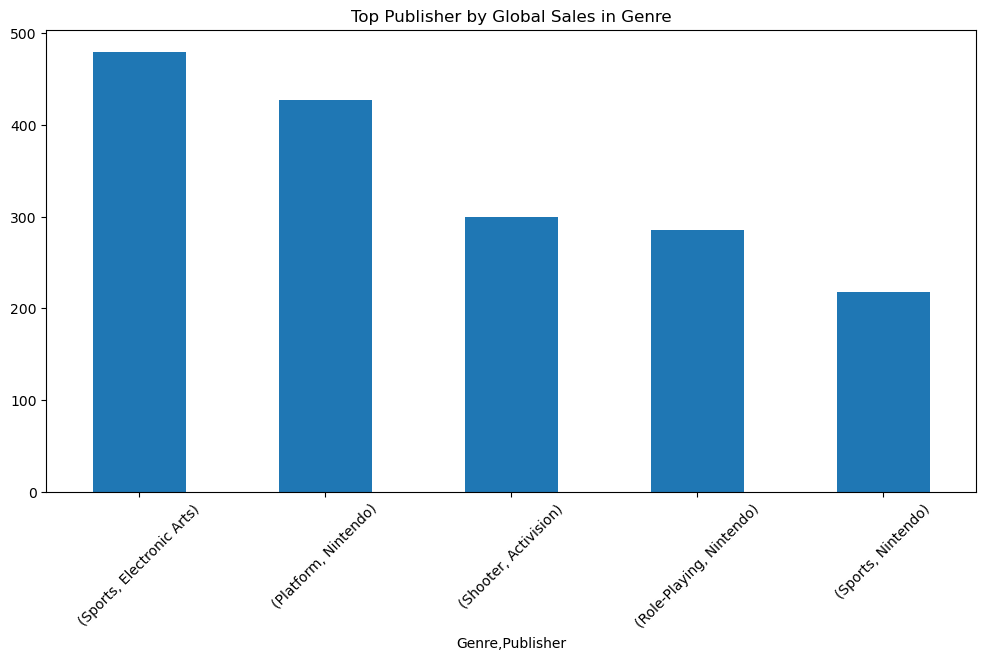

In [12]:
p_genre.plot(kind='bar', figsize=(12, 6))
plt.title('Top Publisher by Global Sales in Genre')
plt.xticks(rotation=45)
plt.show()

In [39]:
p_region = df.groupby('Publisher')[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']].sum()
p_region

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Publisher,,,,
10TACLE Studios,0.07,0.04,0.00,0.00
1C Company,0.01,0.07,0.00,0.02
20th Century Fox Video Games,1.82,0.10,0.00,0.01
2D Boy,0.00,0.03,0.00,0.01
3DO,6.48,3.04,0.00,0.63
...,...,...,...,...
id Software,0.02,0.00,0.00,0.00
imageepoch Inc.,0.00,0.00,0.04,0.00
inXile Entertainment,0.02,0.06,0.00,0.01


In [40]:
top10 = p_region.sum(axis=1).nlargest(10).index
p_region = p_region.loc[top10]
p_region

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Publisher,,,,
Nintendo,816.87,418.74,455.42,95.33
Electronic Arts,595.07,371.27,14.04,129.77
Activision,429.70,215.53,6.54,75.34
Sony Computer Entertainment,265.22,187.72,74.10,80.45
Ubisoft,253.43,163.32,7.50,50.26
Take-Two Interactive,220.49,118.14,5.83,55.24
THQ,208.77,94.73,5.01,32.14
Konami Digital Entertainment,92.16,69.69,91.30,30.31
Sega,109.40,82.00,57.03,24.52


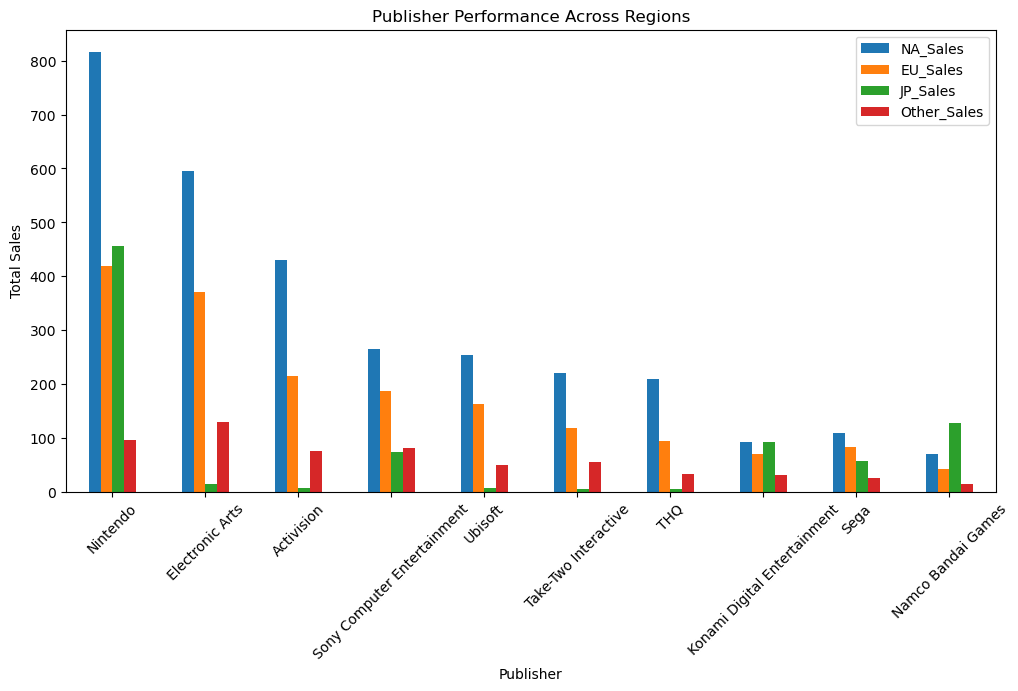

In [41]:
p_region.plot(kind='bar', figsize=(12, 6))
plt.title('Publisher Performance Across Regions')
plt.xlabel('Publisher')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

In [ ]:
#Regional Sales Analysis:

In [42]:
region = df[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']].sum()
region

NA_Sales       4392.95
EU_Sales       2434.13
JP_Sales       1291.02
Other_Sales     797.75
dtype: float64

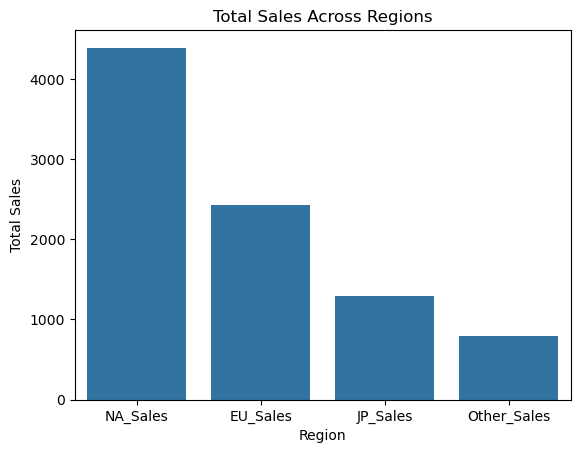

In [63]:
sb.barplot(region)
plt.title('Total Sales Across Regions')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.show()

In [47]:
g=df.groupby('Genre')[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']].sum()
g

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Genre,,,,
Action,877.83,525.00,159.95,187.38
Adventure,105.80,64.13,52.07,16.81
Fighting,223.59,101.32,87.35,36.68
Misc,410.24,215.98,107.76,75.32
Platform,447.05,201.63,130.77,51.59
Puzzle,123.78,50.78,57.31,12.55
Racing,359.42,238.39,56.69,77.27
Role-Playing,327.28,188.06,352.31,59.61
Shooter,582.60,313.27,38.28,102.69


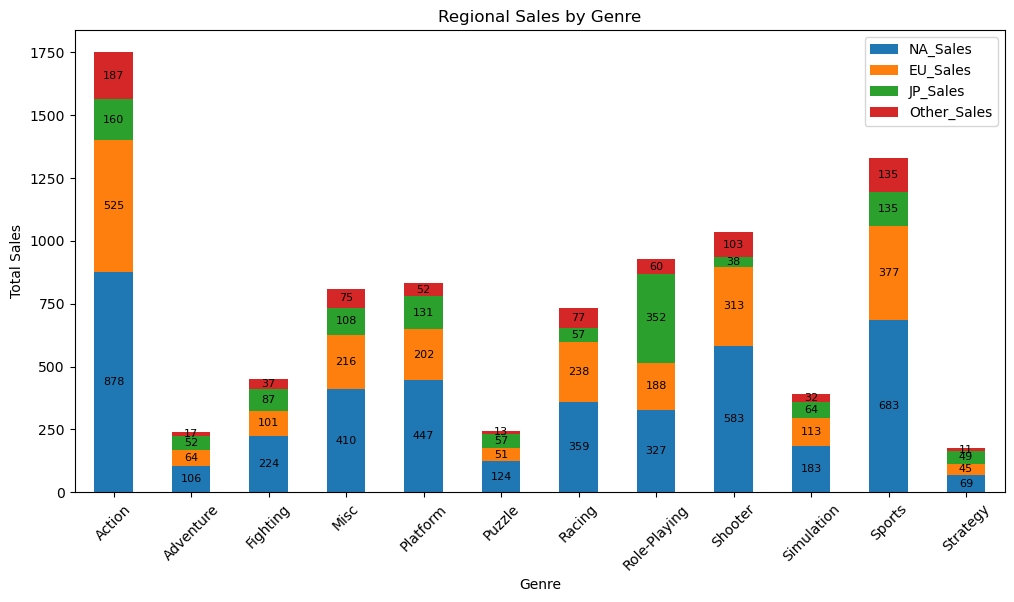

In [62]:
x = g.plot(kind='bar', stacked=True, figsize=(12,6))

for container in x.containers:
    x.bar_label(container, fmt='%.0f', label_type='center', fontsize=8)



plt.title('Regional Sales by Genre')
plt.xlabel('Genre')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.legend()
plt.show()